# 02 — TCX vs Klioner: every body he publishes

**What this notebook does:** repeats notebook 01's independent validation for *all eleven*
bodies in the TU Dresden (Klioner) time-ephemeris set, using the same INPOP19a TCB ephemeris
and planets-only perturber list, and ends with one summary table.

**Why it is separate from 01:** 01 is the deep dive for Earth — three-way TEMPUS / Klioner /
INPOP-internal, because INPOP publishes its own TCG-TCB and Klioner compared against it.
No such internal series exists for the other bodies, so this notebook is a two-way
TEMPUS-vs-Klioner comparison.

**Reference files:** `tcx19a_<tag>_m100_p100_asc_pos_TCB.asc` from
<https://gaia.geo.tu-dresden.de/TimeEphemerides/>, each holding **TCX - TCB in seconds as a
function of TCB** over ~205 yr, derived from INPOP19a. TEMPUS writes TCB - TCX, so TEMPUS is
negated onto Klioner's published convention rather than the other way round.


In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from tempus import jd_split, jd_tt_to_tcb, TimeScalar
from tempus.chebycode import ChebySeries
from tempus.output import read_csv

from nb_utils import (
    DAY_S, JD_1977,
    plot_compare_2timescales,
    remove_1977_step,
    run_tempus_integration,
)

sys.path.insert(0, str(Path("../scripts").resolve()))
from fetch_klioner_asc import fetch_klioner_asc, asc_name

# body label -> (Klioner timescale tag, TEMPUS target)
BODIES = {
    "Sun":     ("TCSun", "SUN"),
    "Mercury": ("TCMer", "MERCURY_BARYCENTER"),
    "Venus":   ("TCVen", "VENUS_BARYCENTER"),
    "Earth":   ("TCG",   "EARTH_CENTER"),
    "Moon":    ("TCL",   "MOON"),
    # Klioner's site names Mars TCMar; fetch_klioner_asc saves it as TCM, the paper's name
    "Mars":    ("TCM", "MARS_BARYCENTER"), 
    "Jupiter": ("TCJup", "JUPITER_BARYCENTER"),
    "Saturn":  ("TCSat", "SATURN_BARYCENTER"),
    "Uranus":  ("TCUra", "URANUS_BARYCENTER"),
    "Neptune": ("TCNep", "NEPTUNE_BARYCENTER"),
    "Pluto":   ("TCPlu", "PLUTO_BARYCENTER"),
}
EPH_DIR = Path("../data/time_ephem")

## 1 · Fetch the Klioner reference files

`scripts/fetch_klioner_asc.py` pulls the eleven `.asc` files (~26 MB total). It skips anything
already on disk and writes atomically, so a partial download can never masquerade as a
complete file — re-running is safe and cheap.

In [2]:
fetch_klioner_asc(EPH_DIR);

  have    tcx19a_TCSun_m100_p100_asc_pos_TCB.asc (1.6 MB)
  have    tcx19a_TCMer_m100_p100_asc_pos_TCB.asc (4.0 MB)
  have    tcx19a_TCVen_m100_p100_asc_pos_TCB.asc (1.5 MB)
  have    tcx19a_TCG_m100_p100_asc_pos_TCB.asc (7.5 MB)
  have    tcx19a_TCL_m100_p100_asc_pos_TCB.asc (7.5 MB)
  have    tcx19a_TCM_m100_p100_asc_pos_TCB.asc (0.8 MB)
  have    tcx19a_TCJup_m100_p100_asc_pos_TCB.asc (0.6 MB)
  have    tcx19a_TCSat_m100_p100_asc_pos_TCB.asc (0.6 MB)
  have    tcx19a_TCUra_m100_p100_asc_pos_TCB.asc (0.5 MB)
  have    tcx19a_TCNep_m100_p100_asc_pos_TCB.asc (0.5 MB)
  have    tcx19a_TCPlu_m100_p100_asc_pos_TCB.asc (0.5 MB)
  have    tcx19a_TCB_m100_p100_asc_pos_TCG.asc (7.5 MB)
  have    tcx19a_TCB_m100_p100_asc_pos_TCM.asc (0.8 MB)


## 2 · Run TEMPUS for every body

One 200-year integration per body on the same grid as notebook 01: INPOP19a TCB, 0.75 d step,
`ext='auto'` (Sun + planet barycentres + Pluto, minus the target itself) — Klioner's own
perturber choice. Each run takes ~1.5 s.

In [5]:
J2000_TT = 2451545.0
eph_file = Path("../data/ephem/inpop19a_TCB_m100_p100_tcg.dat").resolve()

# Anchor J2000.0 TT -> TCB, then +-100 yr; well inside Klioner's JD 2414107..2488955 span.
s_int, s_frac = jd_tt_to_tcb(*jd_split(J2000_TT), eph_file)
start = TimeScalar(int(s_int) - 36525, s_frac)
end   = TimeScalar(int(s_int) + 36525, s_frac)

csv_path = {}
for label, (tag, target) in BODIES.items():
    out = Path(f"../output/nb02_{tag.lower()}_m100_p100_INPOP19aTCB.csv").resolve()
    csv_path[label] = out
    if out.is_file():
        print(f"  have {out.name}")
        continue
    run_tempus_integration(
        eph_file=eph_file, out=out, start=start, end=end, jd_step=0.75, zero=True,
        target=target, ext='auto',
    )

Ephemeris version: INPOP19A
CALCEPH timescale: 2 (TCB)
  zeroed: TCB_minus_TCX = 0 at JD 2443144 + 0.5003725 (TCB) (shift -0.0053957914926560796 s)
Approx. mean drift (TCB-TCX): 0.000192 ms/day
Wrote /home/yan/PythonWorkdir/CNRS_Release/TEMPUS/output/nb02_tcsun_m100_p100_INPOP19aTCB.csv
Ephemeris version: INPOP19A
CALCEPH timescale: 2 (TCB)
  zeroed: TCB_minus_TCX = 0 at JD 2443144 + 0.5003725 (TCB) (shift -92.935131316200227 s)
Approx. mean drift (TCB-TCX): 3.304560 ms/day
Wrote /home/yan/PythonWorkdir/CNRS_Release/TEMPUS/output/nb02_tcmer_m100_p100_INPOP19aTCB.csv
Ephemeris version: INPOP19A
CALCEPH timescale: 2 (TCB)
  zeroed: TCB_minus_TCX = 0 at JD 2443144 + 0.5003725 (TCB) (shift -49.744046541798667 s)
Approx. mean drift (TCB-TCX): 1.768714 ms/day
Wrote /home/yan/PythonWorkdir/CNRS_Release/TEMPUS/output/nb02_tcven_m100_p100_INPOP19aTCB.csv
Ephemeris version: INPOP19A
CALCEPH timescale: 2 (TCB)
  zeroed: TCB_minus_TCX = 0 at JD 2443144 + 0.5003725 (TCB) (shift -35.983421256289411 

## 3 · Per-body comparison

For each body: evaluate Klioner's series at TEMPUS's exact split epochs (never reconstruct the
JD from seconds-past-J2000 — that rounds at ~4e-5 s), align the sign, and difference.

`fix_1977_jump=True` removes Klioner's forward/backward stitching step at the 1977 origin: he
integrated outward in both directions from that epoch and the two branches meet to ~1 ps, which
would otherwise be visable and affect both the drift fit and the residual.


Sun  (TEMPUS SUN  vs  Klioner TCSun)
Klioner linear drift: -2.217295523392129e-12 s/s, -0.00019157433322107995 ms/day
TEMPUS linear drift: -2.217295532105378e-12 s/s, -0.00019157433397390468 ms/day
Detrended TEMPUS min/max: -7.768e-06, 7.625e-06 s


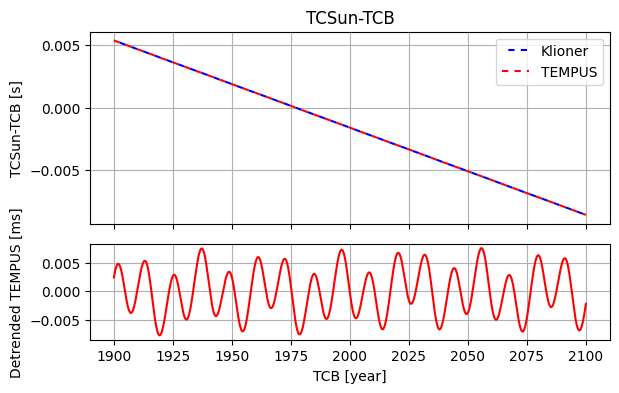

1977 stitching jump removed: -1.998e-15 s (-0.00 ps)


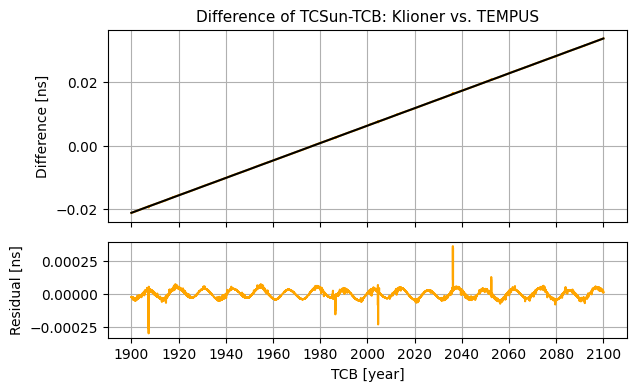

Drift slope (s/s): 8.71369832892843e-21
Average drift per day (ps/day): 0.0007528635356194163
Average drift per century (ns/cy): 0.027498340638499184
Min and Max of detrended TCSun-TCB (ns): -0.0003, 0.0004

Mercury  (TEMPUS MERCURY_BARYCENTER  vs  Klioner TCMer)
Klioner linear drift: -3.8250718364535e-08 s/s, -3.3048620666958244 ms/day
TEMPUS linear drift: -3.825071836453822e-08 s/s, -3.304862066696102 ms/day
Detrended TEMPUS min/max: -1.270e-02, 1.270e-02 s


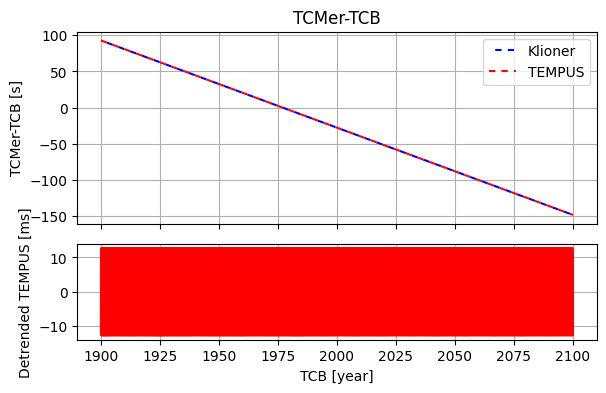

1977 stitching jump removed: -3.741e-12 s (-3.74 ps)


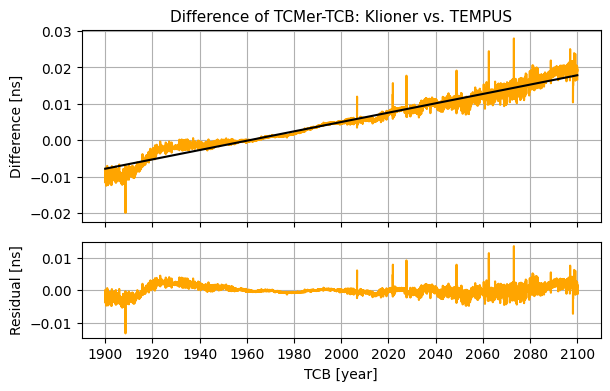

Drift slope (s/s): 4.068929730389613e-21
Average drift per day (ps/day): 0.0003515555287056625
Average drift per century (ns/cy): 0.012840565685974324
Min and Max of detrended TCMer-TCB (ns): -0.0132, 0.0136

Venus  (TEMPUS VENUS_BARYCENTER  vs  Klioner TCVen)
Klioner linear drift: -2.0471258421827607e-08 s/s, -1.7687167276459053 ms/day
TEMPUS linear drift: -2.0471258421830178e-08 s/s, -1.7687167276461273 ms/day
Detrended TEMPUS min/max: -5.926e-04, 6.009e-04 s


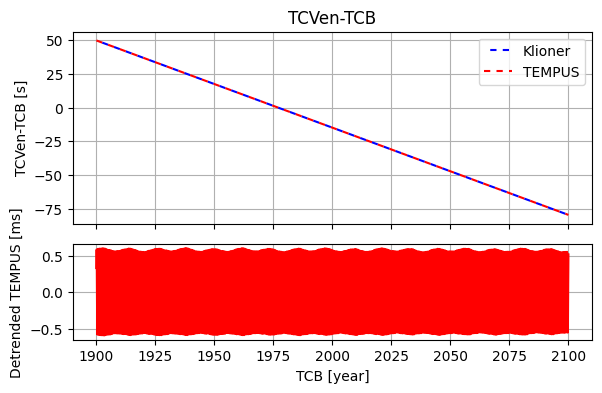

1977 stitching jump removed: 1.689e-12 s (1.69 ps)


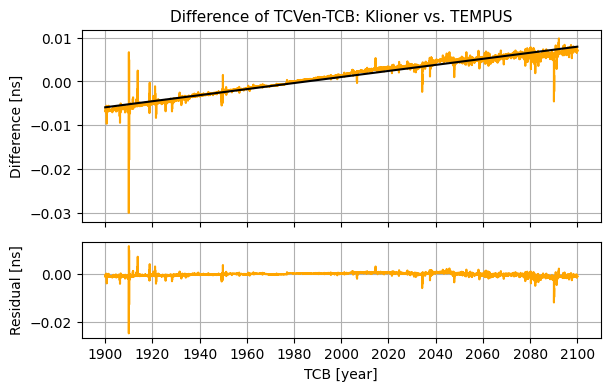

Drift slope (s/s): 2.1929627770013087e-21
Average drift per day (ps/day): 0.00018947198393291307
Average drift per century (ns/cy): 0.006920464213149649
Min and Max of detrended TCVen-TCB (ns): -0.0248, 0.0119

Earth  (TEMPUS EARTH_CENTER  vs  Klioner TCG)
Klioner linear drift: -1.4808266054435181e-08 s/s, -1.2794341871031996 ms/day
TEMPUS linear drift: -1.4808266054439e-08 s/s, -1.2794341871035295 ms/day
Detrended TEMPUS min/max: -1.682e-03, 1.703e-03 s


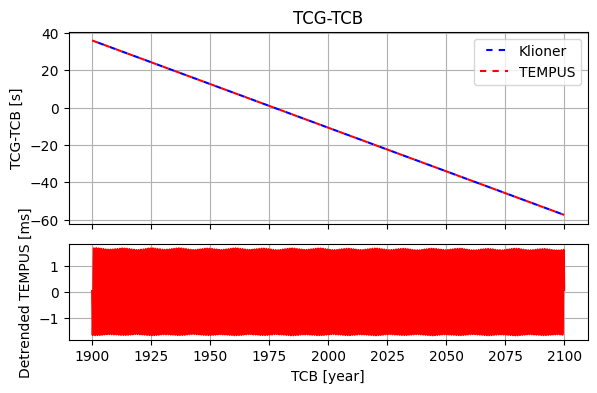

1977 stitching jump removed: -5.363e-12 s (-5.36 ps)


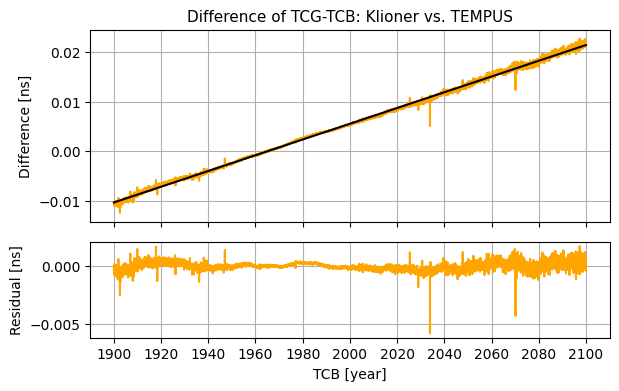

Drift slope (s/s): 5.041069835184289e-21
Average drift per day (ps/day): 0.0004355484337599226
Average drift per century (ns/cy): 0.015908406543081174
Min and Max of detrended TCG-TCB (ns): -0.0059, 0.0018

Moon  (TEMPUS MOON  vs  Klioner TCL)
Klioner linear drift: -1.4825359539291272e-08 s/s, -1.2809110641947659 ms/day
TEMPUS linear drift: -1.4825359539296693e-08 s/s, -1.2809110641952342 ms/day
Detrended TEMPUS min/max: -1.807e-03, 1.824e-03 s


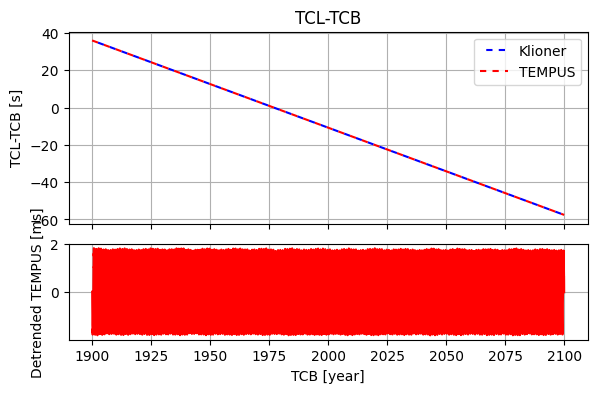

1977 stitching jump removed: 4.977e-12 s (4.98 ps)


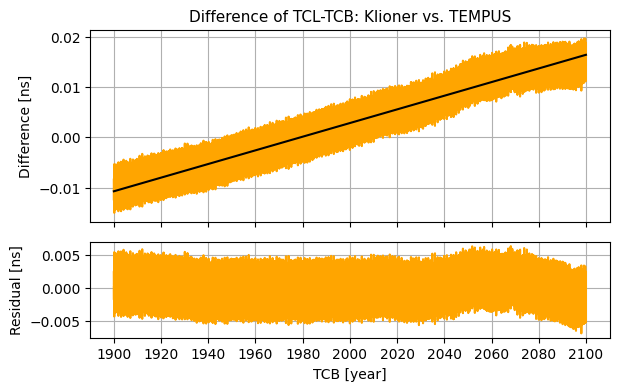

Drift slope (s/s): 4.297518876083801e-21
Average drift per day (ps/day): 0.00037130563089364044
Average drift per century (ns/cy): 0.013561938168390218
Min and Max of detrended TCL-TCB (ns): -0.0069, 0.0063

Mars  (TEMPUS MARS_BARYCENTER  vs  Klioner TCM)
Klioner linear drift: -9.719367252115982e-09 s/s, -0.8397533305828209 ms/day
TEMPUS linear drift: -9.719367252119369e-09 s/s, -0.8397533305831134 ms/day
Detrended TEMPUS min/max: -1.154e-02, 1.152e-02 s


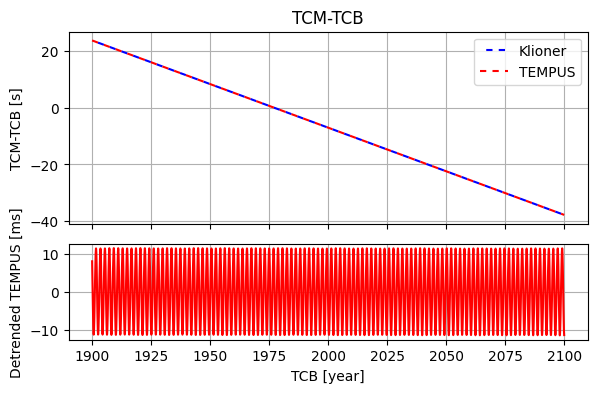

1977 stitching jump removed: 1.012e-13 s (0.10 ps)


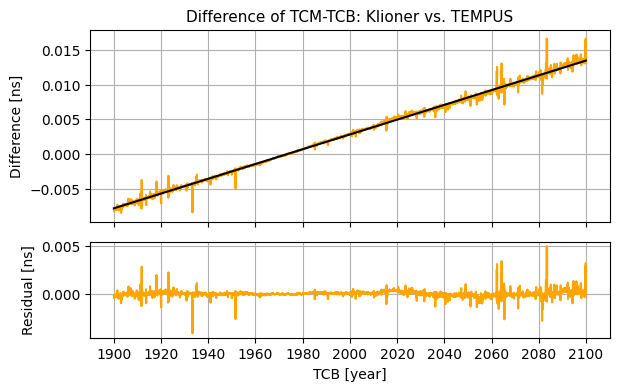

Drift slope (s/s): 3.3713196599573786e-21
Average drift per day (ps/day): 0.00029128201862031755
Average drift per century (ns/cy): 0.0106390757301071
Min and Max of detrended TCM-TCB (ns): -0.0041, 0.0050

Jupiter  (TEMPUS JUPITER_BARYCENTER  vs  Klioner TCJup)
Klioner linear drift: -2.8452664008630833e-09 s/s, -0.2458310170345704 ms/day
TEMPUS linear drift: -2.8452664008703683e-09 s/s, -0.24583101703519983 ms/day
Detrended TEMPUS min/max: -1.136e-02, 1.150e-02 s


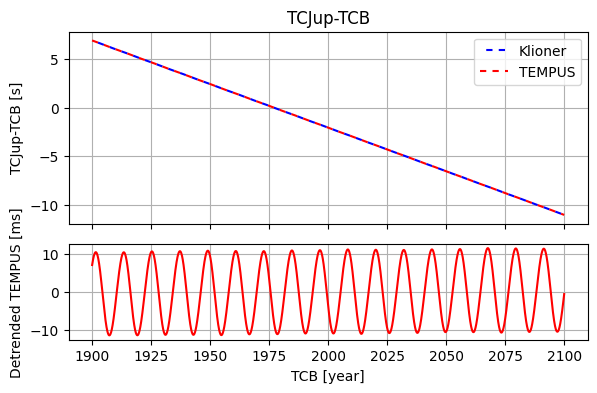

1977 stitching jump removed: 9.164e-15 s (0.01 ps)


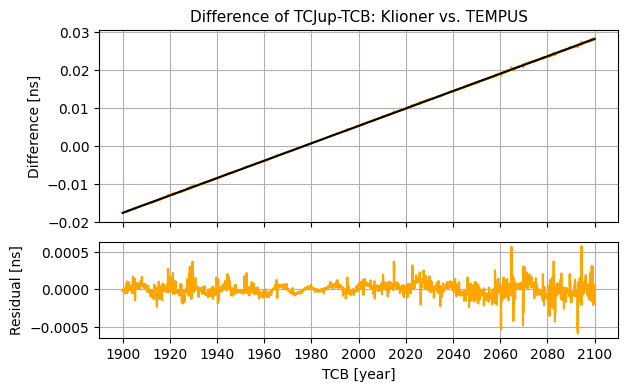

Drift slope (s/s): 7.284648275420055e-21
Average drift per day (ps/day): 0.0006293936109962927
Average drift per century (ns/cy): 0.022988601641639593
Min and Max of detrended TCJup-TCB (ns): -0.0006, 0.0006

Saturn  (TEMPUS SATURN_BARYCENTER  vs  Klioner TCSat)
Klioner linear drift: -1.5540403146941733e-09 s/s, -0.1342690831895766 ms/day
TEMPUS linear drift: -1.5540403146958275e-09 s/s, -0.1342690831897195 ms/day
Detrended TEMPUS min/max: -1.807e-02, 1.784e-02 s


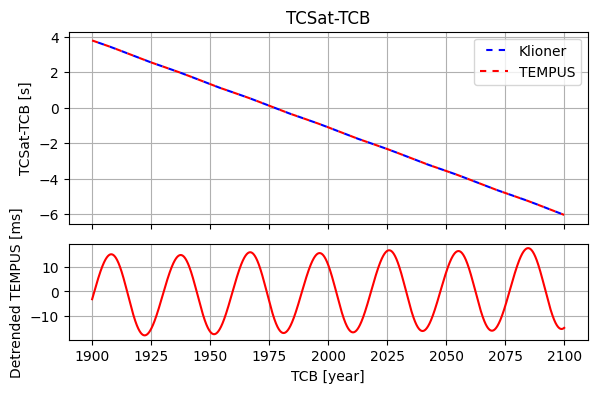

1977 stitching jump removed: 5.721e-16 s (0.00 ps)


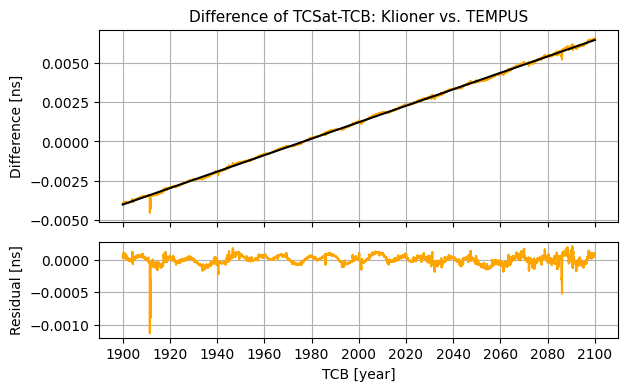

Drift slope (s/s): 1.6537363428650888e-21
Average drift per day (ps/day): 0.0001428828200235437
Average drift per century (ns/cy): 0.005218795001359933
Min and Max of detrended TCSat-TCB (ns): -0.0011, 0.0002

Uranus  (TEMPUS URANUS_BARYCENTER  vs  Klioner TCUra)
Klioner linear drift: -7.730389206347405e-10 s/s, -0.06679056274284158 ms/day
TEMPUS linear drift: -7.730389206353603e-10 s/s, -0.06679056274289513 ms/day
Detrended TEMPUS min/max: -2.064e-02, 2.266e-02 s


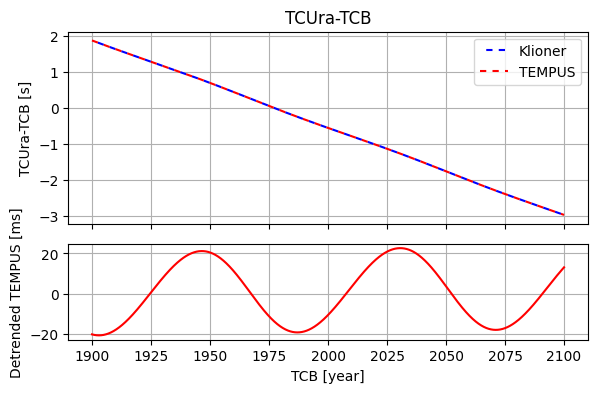

1977 stitching jump removed: 2.526e-16 s (0.00 ps)


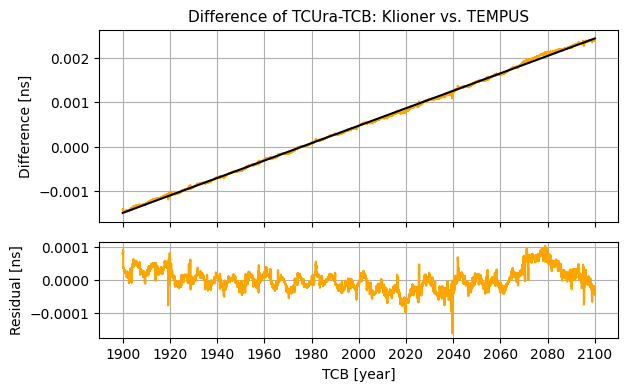

Drift slope (s/s): 6.197947583115943e-22
Average drift per day (ps/day): 5.355026711812175e-05
Average drift per century (ns/cy): 0.001955923506489397
Min and Max of detrended TCUra-TCB (ns): -0.0002, 0.0001

Neptune  (TEMPUS NEPTUNE_BARYCENTER  vs  Klioner TCNep)
Klioner linear drift: -4.928823899482493e-10 s/s, -0.04258503849152874 ms/day
TEMPUS linear drift: -4.92882389948628e-10 s/s, -0.04258503849156146 ms/day
Detrended TEMPUS min/max: -4.240e-03, 5.413e-03 s


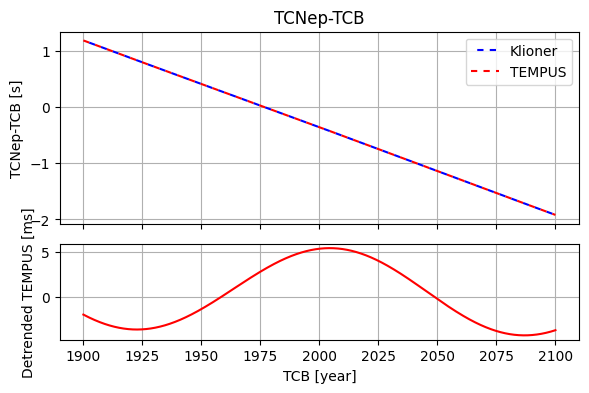

1977 stitching jump removed: 1.154e-15 s (0.00 ps)


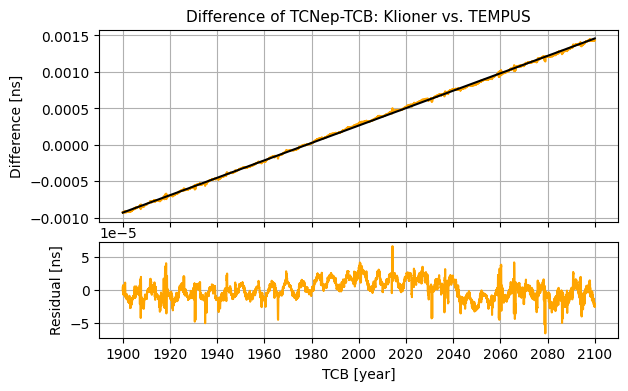

Drift slope (s/s): 3.7822513038359225e-22
Average drift per day (ps/day): 3.267865126514237e-05
Average drift per century (ns/cy): 0.001193587737459325
Min and Max of detrended TCNep-TCB (ns): -0.0001, 0.0001

Pluto  (TEMPUS PLUTO_BARYCENTER  vs  Klioner TCPlu)
Klioner linear drift: -4.3223230485313687e-10 s/s, -0.03734487113931102 ms/day
TEMPUS linear drift: -4.3223230485346604e-10 s/s, -0.037344871139339465 ms/day
Detrended TEMPUS min/max: -8.733e-02, 1.438e-01 s


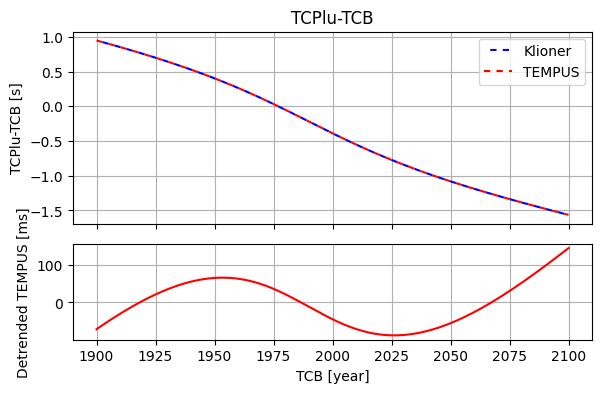

1977 stitching jump removed: -8.117e-16 s (-0.00 ps)


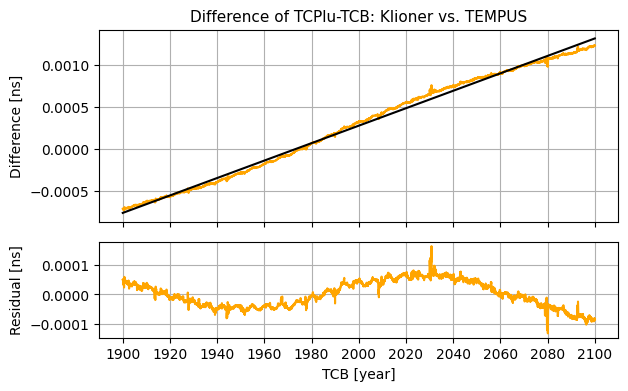

Drift slope (s/s): 3.292085388092248e-22
Average drift per day (ps/day): 2.8443617753117024e-05
Average drift per century (ns/cy): 0.0010389031384325992
Min and Max of detrended TCPlu-TCB (ns): -0.0001, 0.0002


In [ ]:
summary = {}

for label, (tag, target) in BODIES.items():
    cols, _ = read_csv(csv_path[label])
    jdi, jdf = cols["JD_int"], cols["JD_frac"]
    et = cols["SecondsPastJ2000"]

    # Klioner's file holds TCX - TCB; TEMPUS writes TCB - TCX, so TEMPUS is the
    # one negated and his published series is left untouched.
    tempus = -cols["TCB_minus_TCX"]
    klioner = ChebySeries.from_asc(str(EPH_DIR / asc_name(tag))).evaluate(jdi, jdf)

    # line below would be used to align the offsets, if we didnt use --zero=True in run_tempus_integration
    #tempus = tempus - tempus[0] + klioner[0]      # share a zero; slopes are unaffected 

    diff, jump = remove_1977_step(jdi, jdf, klioner - tempus)
    slope, icpt, *_ = stats.linregress(et, diff)
    resid = diff - (slope * et + icpt)

    summary[label] = dict(
        tag=tag,
        tempus_msday=stats.linregress(et, tempus).slope * DAY_S * 1e3,
        klioner_msday=stats.linregress(et, klioner).slope * DAY_S * 1e3,
        diff_ss=slope,
        diff_nscy=slope * DAY_S * 365.25 * 100 * 1e9,
        resid_peak_ps=np.max(np.abs(resid)) * 1e12,
        jump_ps=jump * 1e12,
    )

    print(f"\n{'='*78}\n{label}  (TEMPUS {target}  vs  Klioner {tag})\n{'='*78}")
    plot_compare_2timescales(et, klioner, f"Klioner", tempus, f"TEMPUS",
                             label=f"{tag}-TCB", x_tick=20, overview=True,
                             fix_1977_jump=True, paper_mode=True)

## 4 · Summary

`TEMPUS` and `Klioner` columns are the secular rates of TCX-TCB itself — they must agree to
many digits, since both describe the same physics on the same ephemeris. The validation is in
the last two columns: the residual drift after differencing, and the peak of what remains once
that drift is removed.

In [7]:
header = (f"{'body':9s} {'tag':7s} {'TEMPUS':>14s} {'Klioner':>14s} {'TCB-TCX':>12s} "
          f"{'diff drift':>12s} {'diff drift':>12s} {'resid peak':>11s} {'1977 step':>10s}")

print(header)
print(f"{'':9s} {'':7s} {'[ms/day]':>14s} {'[ms/day]':>14s} {'[1e-10 s/s]':>12s} {'[1e-21 s/s]':>12s} {'[ns/cy]':>12s} {'[ps]':>11s} {'[ps]':>10s}")
print('-' * len(header))
for label, s in summary.items():
    print(f"{label:9s} {s['tag']:7s} {s['tempus_msday']:14.10f} {s['klioner_msday']:14.10f} "
          f"{-s['tempus_msday'] / (DAY_S * 1e3) / 1e-10:12.3f} "
          f"{s['diff_ss']/1e-21:12.1f} {s['diff_nscy']:12.3f} {s['resid_peak_ps']:11.1f} {s['jump_ps']:10.2f}")

body      tag             TEMPUS        Klioner      TCB-TCX   diff drift   diff drift  resid peak  1977 step
                        [ms/day]       [ms/day]  [1e-10 s/s]  [1e-21 s/s]      [ns/cy]        [ps]       [ps]
-------------------------------------------------------------------------------------------------------------
Sun       TCSun    -0.0001915743  -0.0001915743        0.022          8.7        0.027         0.4      -0.00
Mercury   TCMer    -3.3048620667  -3.3048620667      382.507          4.1        0.013        13.6      -3.74
Venus     TCVen    -1.7687167276  -1.7687167276      204.713          2.2        0.007        24.8       1.69
Earth     TCG      -1.2794341871  -1.2794341871      148.083          5.0        0.016         5.9      -5.36
Moon      TCL      -1.2809110642  -1.2809110642      148.254          4.3        0.014         6.9       4.98
Mars      TCM      -0.8397533306  -0.8397533306       97.194          3.4        0.011         5.0       0.10
Jupiter   